# Network Analysis Project: e-mail networks (email-Eu-core)
## Section 5.3 (RQ3, departments as communication boundaries)

**RQ3: Are departments real boundaries of communication?**

This notebook tests six hypotheses. Each one follows the report rule **A → B → C**: phenomenon → measure → what it means for e-mail here.

| # | Hypothesis | Measures (B) | Test |
|---|---|---|---|
| **H1** | Members e-mail colleagues of their **own department** more than chance | share of within-department edges, tie-density ratio, **assortativity** by department | **QAP** (5,000 permutations) |
| **H2** | The groups that appear from e-mail (**communities**) match the **departments** | Louvain communities, modularity Q (Louvain vs. departments), **NMI**, **ARI** | 100 degree-preserving rewired networks; NMI vs. shuffled communities |
| **H2b** | The community result is **stable** (reliability) | Q, NMI, ARI over 20 Louvain seeds and 5 resolution values | sensitivity analysis |
| **H3** | Departments are **closed**, but some much more than others | **E–I index** per department (Krackhardt & Stern) | label permutations + Benjamini–Hochberg correction |
| **H4** | Members outside the department's LCC (Section 5.1) actually e-mail **other** departments | breakdown of members of the 4 largest departments | descriptive (checks the claim in 5.1) |
| **H5** | E-mails **inside** a department are answered more often than e-mails **across** departments | reciprocity within vs. between | label permutations |
| *extra* | Which departments talk to each other? | department × department mixing matrix (+ Gephi file) | descriptive, optional |

- Every table is saved in `results/` as **CSV + LaTeX**, every figure as **PNG (200 dpi)**, and all key numbers in `results/rq3_summary.json`.

**Shared rules respected:** same loader as Notebook 1 (`load_networks.py`), directed and unweighted network, self-loops removed, isolates kept, OR rule for the undirected version, **seed = 42** everywhere.

## Step 1: Data and the shared loader

- Downloads the two SNAP files into `data/` **only if they are not already there**.
- The second cell writes `load_networks.py`, the group's **shared loader**. It is an **exact copy** of the cell (Notebook 1), so running it never changes anything: it just makes sure the file exists in this session (e.g. a fresh Colab runtime).

In [1]:
import urllib.request
from pathlib import Path

DATA = Path("data")
DATA.mkdir(exist_ok=True)

FILES = {
    "email-Eu-core.txt.gz": "https://snap.stanford.edu/data/email-Eu-core.txt.gz",
    "email-Eu-core-department-labels.txt.gz": "https://snap.stanford.edu/data/email-Eu-core-department-labels.txt.gz",
}
for name, url in FILES.items():
    target = DATA / name
    if target.exists():
        print(f"already there: {target}")
    else:
        print(f"downloading {name} ...")
        urllib.request.urlretrieve(url, target)

downloading email-Eu-core.txt.gz ...
downloading email-Eu-core-department-labels.txt.gz ...


In [2]:
%%writefile load_networks.py
"""Shared loader for the email-Eu-core networks (used by every group member)."""
import gzip                       # to read the compressed .gz files directly
from collections import Counter   # to count how many people are in each department
from pathlib import Path          # to build file paths that work on every computer

import networkx as nx

DATA = Path(__file__).parent / "data"  # the data folder next to this file
SEED = 42      # fixed random seed: everyone gets the same "random" results
N_DEPTS = 4    # number of largest departments analysed as separate networks


def _open(path):
    """Open a file as text, whether it is compressed (.gz) or not."""
    path = Path(path)
    return gzip.open(path, "rt") if path.suffix == ".gz" else open(path)


def load_whole():
    """Build the whole institution network as a directed graph with department labels."""
    G = nx.DiGraph()  # DiGraph = directed graph (edges have a direction)

    # 1) Add every person as a node, with their department stored as attribute "dept".
    #    Doing this first also keeps people who never sent/received an e-mail (isolates).
    with _open(DATA / "email-Eu-core-department-labels.txt.gz") as f:
        for line in f:
            if line.strip():                       # skip empty lines
                node, dept = map(int, line.split())
                G.add_node(node, dept=dept)

    # 2) Add one directed edge u -> v for every line "u v" (u sent at least one e-mail to v).
    #    A DiGraph keeps at most one edge per ordered pair, so the network is unweighted.
    with _open(DATA / "email-Eu-core.txt.gz") as f:
        for line in f:
            if line.strip():
                u, v = map(int, line.split()[:2])
                G.add_edge(u, v)

    # 3) Remove self-loops (e-mails a person sent to themselves).
    G.remove_edges_from(list(nx.selfloop_edges(G)))
    return G


def largest_departments(G, k=N_DEPTS):
    """Return the IDs of the k largest departments (ties broken by the smaller department ID)."""
    sizes = Counter(d for _, d in G.nodes(data="dept"))  # {department: number of members}
    ranked = sorted(sizes.items(), key=lambda x: (-x[1], x[0]))  # biggest first
    return [d for d, _ in ranked[:k]]


def dept_network(G, dept):
    """Network of one department: its members + only the e-mails among them (induced subgraph)."""
    members = [n for n, d in G.nodes(data="dept") if d == dept]
    return G.subgraph(members).copy()  # .copy() makes it an independent graph


def load_all():
    """Return a dictionary with the whole network and the N_DEPTS largest department networks."""
    G = load_whole()
    nets = {"whole": G}
    for dept in largest_departments(G):
        nets[f"dept{dept}"] = dept_network(G, dept)  # e.g. "dept4" = department with ID 4
    return nets


if __name__ == "__main__":
    # Quick check when the file is run directly: print the size of every network.
    for name, H in load_all().items():
        print(f"{name:7s}  nodes={H.number_of_nodes():5d}  edges={H.number_of_edges():6d}")

Writing load_networks.py


## Step 2: Settings

All parameters in one place. **Do not change `SEED`** (group rule). The numbers of permutations / random networks are the ones to report in the text and captions.

In [3]:
import importlib
import json
import math
import shutil
import time

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

import load_networks
importlib.reload(load_networks)
from load_networks import SEED, dept_network, largest_departments, load_whole

N_PERM = 5000            # QAP / label permutations (H1, H3, H5)
N_NULL = 100             # degree-preserving rewired networks (H2)
N_SEEDS = 20             # Louvain seeds for the stability check (H2b)
N_NMI_NULL = 1000        # shuffled-community baselines for NMI (H2)
RESOLUTIONS = [0.5, 1.0, 1.5, 2.0, 3.0]   # Louvain resolution values (H2b)
MIN_DEPT_TEST = 5        # departments smaller than this are reported but not tested (H3)
ALPHA = 0.05             # significance level

OUT = Path("results")
OUT.mkdir(exist_ok=True)

# Figure style (matches a 12pt Times report; colours checked for colour-blind readers)
plt.rcParams.update({"font.family": "serif", "font.size": 9, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.edgecolor": "#8a8985",
                     "axes.labelcolor": "#2b2b29", "xtick.color": "#52514e", "ytick.color": "#52514e"})
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#8a8985"

summary = {"seed": SEED, "n_perm": N_PERM, "n_null": N_NULL}   # every key number, for the report


def save_table(df, name, caption_hint, float_format="%.3f", index=True):
    """Save a table as CSV and LaTeX (booktabs) in results/."""
    df.to_csv(OUT / f"{name}.csv", index=index)
    df.to_latex(OUT / f"{name}.tex", float_format=float_format, index=index, na_rep="--")
    print(f"saved results/{name}.csv and .tex  ({caption_hint})")


def p_upper(null, observed):
    """One-sided permutation p-value: share of null values >= observed (with +1 correction)."""
    null = np.asarray(null)
    return (np.sum(null >= observed) + 1) / (len(null) + 1)


def p_lower(null, observed):
    """One-sided permutation p-value: share of null values <= observed (with +1 correction)."""
    null = np.asarray(null)
    return (np.sum(null <= observed) + 1) / (len(null) + 1)


def benjamini_hochberg(pvalues):
    """Benjamini-Hochberg adjusted p-values (controls the false discovery rate)."""
    p = np.asarray(pvalues, dtype=float)
    m = len(p)
    order = np.argsort(p)
    ranked = p[order] * m / np.arange(1, m + 1)
    adjusted = np.minimum.accumulate(ranked[::-1])[::-1]
    out = np.empty(m)
    out[order] = np.minimum(adjusted, 1.0)
    return out

## Step 3: Load the network and check it against Notebook 1

We work on the **whole network** (all 1,005 members, all 42 departments). For fast permutation tests, nodes are numbered 0 … n−1 and edges are stored as NumPy arrays.

**Expected (Notebook 1, Table 1):** 1,005 nodes, 24,929 directed edges, reciprocity 0.711, LCC share 0.981.

In [4]:
G = load_whole()                       # directed, unweighted, no self-loops, isolates kept
U = G.to_undirected()                  # OR rule: A-B linked if A->B or B->A

nodes = sorted(G.nodes())
index = {v: i for i, v in enumerate(nodes)}
n = len(nodes)

dept_ids = np.array(sorted({d for _, d in G.nodes(data="dept")}))      # real department IDs
dept = np.searchsorted(dept_ids, [G.nodes[v]["dept"] for v in nodes])  # code 0..K-1 per node
K = len(dept_ids)
sizes = np.bincount(dept, minlength=K)

# Directed edges (u -> v) and undirected edges (OR rule) as index arrays
src, dst = np.array([(index[u], index[v]) for u, v in G.edges()]).T
usrc, udst = np.array([(index[u], index[v]) for u, v in U.edges()]).T
m_dir, m_und = len(src), len(usrc)

# Reciprocity flag per directed edge: does the reverse e-mail link also exist?
edge_set = set(zip(src.tolist(), dst.tolist()))
reciprocated = np.array([(v, u) in edge_set for u, v in zip(src.tolist(), dst.tolist())])

isolates = sorted(nx.isolates(G))
lcc = max(nx.connected_components(U), key=len)

checks = pd.DataFrame({
    "this notebook": [n, m_dir, m_und, K, len(isolates), len(lcc) / n, reciprocated.mean()],
    "Notebook 1 / SNAP": [1005, 24929, None, 42, None, 0.981, 0.711],
}, index=["nodes", "directed edges", "undirected (OR) edges", "departments",
          "isolates (no e-mail at all)", "LCC share", "reciprocity"])
display(checks)

assert abs(reciprocated.mean() - nx.reciprocity(G)) < 1e-9   # our fast flag = NetworkX

summary.update({"nodes": n, "edges_directed": m_dir, "edges_undirected": m_und,
                "departments": K, "isolates": len(isolates)})

,this notebook,Notebook 1 / SNAP
nodes,1005.000000,1005.000
directed edges,24929.000000,24929.000
undirected (OR) edges,16064.000000,NaN
departments,42.000000,42.000
isolates (no e-mail at all),19.000000,NaN
LCC share,0.981095,0.981
reciprocity,0.711220,0.711


### Department sizes

Departments differ a lot in size. This matters for every measure below: a tiny department *cannot* have many internal ties. Departments with fewer than `MIN_DEPT_TEST` members are reported but not tested in H3.

In [5]:
dept_sizes = pd.Series(sizes, index=[f"Department {d}" for d in dept_ids]).sort_values(ascending=False)
print(f"{K} departments; size min = {sizes.min()}, median = {np.median(sizes):.0f}, max = {sizes.max()}")
print(f"departments with < {MIN_DEPT_TEST} members: {(sizes < MIN_DEPT_TEST).sum()}")
print(f"4 largest departments: {largest_departments(G)} -> together {np.sort(sizes)[-4:].sum()} members "
      f"({np.sort(sizes)[-4:].sum() / n:.1%} of the institution)")
display(dept_sizes.to_frame("members").T)
summary["dept_size_min_median_max"] = [int(sizes.min()), float(np.median(sizes)), int(sizes.max())]

42 departments; size min = 1, median = 14, max = 109
departments with < 5 members: 7
4 largest departments: [4, 14, 1, 21] -> together 327 members (32.5% of the institution)


,Department 4,Department 14,Department 1,Department 21,Department 15,Department 7,Department 0,Department 10,Department 17,Department 9,...,Department 24,Department 25,Department 29,Department 30,Department 40,Department 12,Department 39,Department 41,Department 18,Department 33
members,109,92,65,61,55,51,49,39,35,32,...,6,6,5,4,4,3,3,2,1,1


## Step 4 — H1: Do members e-mail inside their own department more than chance?

**A (phenomenon):** *homophily by department*: people may write mostly to colleagues of their own department.

**B (measures), all on the directed network:**
1. **Share of within-department edges** vs. the share expected if links were random (= share of all ordered pairs that are same-department pairs).
2. **Tie-density ratio**: density of links among same-department pairs ÷ density among different-department pairs. Reads as "a same-department pair is *x* times more likely to be linked".
3. **Attribute assortativity** by department (`nx.attribute_assortativity_coefficient`, Newman 2003): +1 = all e-mails stay inside departments, 0 = random mixing, <0 = people prefer other departments.
4. **QAP correlation test** (Krackhardt 1988), the core hypothesis test:
   - H0: sharing a department is not associated with e-mailing; H1: same-department pairs are more likely to e-mail.
   - A = adjacency matrix (directed), S = 1 if two members share a department.
   - Observed r = Pearson correlation of all **n(n−1) off-diagonal cells** of A and S (A is directed, so both triangles).
   - Permute rows **and** columns of S together 5,000 times and recompute r. p = share of permuted r ≥ observed (with the +1 correction, so p is never exactly 0).

**Why QAP?** E-mail links are not independent observations (the same person appears in many pairs). QAP keeps the structure of both matrices and only breaks the link between them.

**Speed trick (exact, not an approximation):** permuting rows and columns of S together is the same as shuffling the department labels across members (department sizes stay the same). The cell checks this equivalence on real matrix permutations before using it.

In [6]:
N_pairs = n * (n - 1)                            # ordered pairs (directed, no self-pairs)
same_pairs = int(np.sum(sizes * (sizes - 1)))   # ordered same-department pairs (fixed under permutation)


def qap_r(within_edges):
    """Pearson r between off-diagonal cells of A and S, from counts (exact formula for 0/1 vectors)."""
    num = N_pairs * within_edges - m_dir * same_pairs
    den = math.sqrt(m_dir * (N_pairs - m_dir) * same_pairs * (N_pairs - same_pairs))
    return num / den


def assortativity_fast(lab_src, lab_dst):
    """Newman's attribute assortativity from the K x K mixing matrix (same formula as NetworkX)."""
    M = np.zeros((K, K))
    np.add.at(M, (lab_src, lab_dst), 1)
    M /= M.sum()
    ab = float(np.sum(M.sum(axis=1) * M.sum(axis=0)))
    return (float(np.trace(M)) - ab) / (1 - ab)


# --- Observed values -------------------------------------------------------------
within_dir = dept[src] == dept[dst]
w_obs = int(within_dir.sum())
share_within = w_obs / m_dir
share_expected = same_pairs / N_pairs
density_within = w_obs / same_pairs
density_between = (m_dir - w_obs) / (N_pairs - same_pairs)
assort_obs = nx.attribute_assortativity_coefficient(G, "dept")

# QAP observed r computed the slow, "textbook" way on the full matrices ...
A = nx.to_numpy_array(G, nodelist=nodes, dtype=np.int8)
S = (dept[:, None] == dept[None, :]).astype(np.int8)
off = ~np.eye(n, dtype=bool)
r_obs = np.corrcoef(A[off], S[off])[0, 1]

# ... and checked against the fast formulas
assert abs(r_obs - qap_r(w_obs)) < 1e-9
assert abs(assort_obs - assortativity_fast(dept[src], dept[dst])) < 1e-9
check_rng = np.random.default_rng(SEED)
for _ in range(3):                               # real QAP permutations of S == label shuffles
    p = check_rng.permutation(n)
    r_matrix = np.corrcoef(A[off], S[np.ix_(p, p)][off])[0, 1]
    lab = dept[p]
    assert abs(r_matrix - qap_r(int(np.sum(lab[src] == lab[dst])))) < 1e-9
print("checks passed: matrix QAP == fast label-permutation QAP; fast assortativity == NetworkX")
del A, S, off

checks passed: matrix QAP == fast label-permutation QAP; fast assortativity == NetworkX


### One shared permutation loop (H1, H3, H5)

To save time, the **same 5,000 label permutations** are used for every permutation test in this notebook: QAP r and assortativity (H1), E–I indices (H3) and reciprocity within vs. between (H5). Each test is still valid on its own; using the same permutations just makes them consistent with each other.

In [7]:
def ei_counts(lab):
    """Undirected (OR) edges: internal ties per department, external ties per department."""
    same = lab[usrc] == lab[udst]
    internal = np.bincount(lab[usrc][same], minlength=K)
    external = (np.bincount(lab[usrc][~same], minlength=K)
                + np.bincount(lab[udst][~same], minlength=K))
    return internal, external, int(same.sum())


def ei_index(internal, external):
    """Krackhardt & Stern E-I index = (E - I) / (E + I); NaN if a department has no ties."""
    total = internal + external
    with np.errstate(invalid="ignore", divide="ignore"):
        return np.where(total > 0, (external - internal) / total, np.nan)


rng = np.random.default_rng(SEED)
null_r = np.empty(N_PERM)
null_assort = np.empty(N_PERM)
null_ei_dept = np.empty((N_PERM, K))
null_ei_whole = np.empty(N_PERM)
null_recip_diff = np.empty(N_PERM)

t0 = time.time()
for k in range(N_PERM):
    lab = rng.permutation(dept)                       # shuffle departments across members
    same_dir = lab[src] == lab[dst]
    null_r[k] = qap_r(int(same_dir.sum()))
    null_assort[k] = assortativity_fast(lab[src], lab[dst])
    internal, external, same_und = ei_counts(lab)
    null_ei_dept[k] = ei_index(internal, external)
    null_ei_whole[k] = (m_und - 2 * same_und) / m_und
    null_recip_diff[k] = reciprocated[same_dir].mean() - reciprocated[~same_dir].mean()
print(f"{N_PERM} permutations done in {time.time() - t0:.0f} s")

5000 permutations done in 20 s


In [8]:
p_r = p_upper(null_r, r_obs)
p_assort = p_upper(null_assort, assort_obs)

h1 = pd.DataFrame({
    "observed": [share_within, share_expected, density_within, density_between,
                 density_within / density_between, assort_obs, r_obs],
    "null mean": [None, None, None, None, None, null_assort.mean(), null_r.mean()],
    "null 95% range": [None, None, None, None, None,
                       f"[{np.percentile(null_assort, 2.5):.3f}, {np.percentile(null_assort, 97.5):.3f}]",
                       f"[{np.percentile(null_r, 2.5):.3f}, {np.percentile(null_r, 97.5):.3f}]"],
    "p-value": [None, None, None, None, None, p_assort, p_r],
}, index=["Share of edges within departments", "Share expected by chance",
          "Density, same-department pairs", "Density, different-department pairs",
          "Density ratio (same / different)", "Assortativity by department r",
          "QAP correlation r"])
display(h1)
save_table(h1, "table_5_3_H1_homophily", "H1: homophily by department, QAP")

print(f"\nQAP: r = {r_obs:.3f}, {N_PERM} permutations, largest permuted r = {null_r.max():.3f}, p = {p_r:.4f}")
print(f"A same-department pair is {density_within / density_between:.1f} times more likely to be linked.")
summary["H1"] = {"share_within": share_within, "share_expected": share_expected,
                 "density_within": density_within, "density_between": density_between,
                 "density_ratio": density_within / density_between,
                 "assortativity": assort_obs, "assortativity_p": p_assort,
                 "qap_r": r_obs, "qap_null_max": float(null_r.max()), "qap_p": p_r}

,observed,null mean,null 95% range,p-value
Share of edges within departments,0.346785,NaN,None,NaN
Share expected by chance,0.046667,NaN,None,NaN
"Density, same-department pairs",0.183592,NaN,None,NaN
"Density, different-department pairs",0.016928,NaN,None,NaN
Density ratio (same / different),10.845212,NaN,None,NaN
Assortativity by department r,0.314073,-0.002372,"[-0.005, 0.001]",0.0002
QAP correlation r,0.226464,0.000038,"[-0.004, 0.004]",0.0002


saved results/table_5_3_H1_homophily.csv and .tex  (H1: homophily by department, QAP)

QAP: r = 0.226, 5000 permutations, largest permuted r = 0.010, p = 0.0002
A same-department pair is 10.8 times more likely to be linked.


## Step 5 — H2: Do the groups found from e-mail match the departments?

**A:** if departments are real boundaries, a community-detection algorithm that only sees *who e-mails whom* (and knows nothing about departments) should rediscover them.

**B (measures), on the undirected (OR) network:**
- **Louvain communities** (`nx.community.louvain_communities`, Blondel et al. 2008, resolution γ = 1, seed 42) and their **modularity Q**: how much more the e-mail links stay *inside* groups than expected for random links with the same degrees.
- **Q of the department partition**: the same modularity, using the 42 real departments as the groups. If it is close to Louvain's Q, departments are almost as good a split as the best one the algorithm finds.
- **NMI** (normalised mutual information, 0 = unrelated, 1 = identical) and **ARI** (adjusted Rand index, 0 = chance level, 1 = identical) between Louvain communities and departments.
  - Computed on the **non-isolated members only**: Louvain puts each isolate in its own community, which would artificially change NMI/ARI. Isolates carry no information about communication.
  - NMI tends to grow with the number of groups, so it is compared with NMI of **shuffled communities** (same community sizes, random members). ARI is already corrected for chance.

**Tests:** both Q values are compared with **100 degree-preserving rewired networks** (`nx.double_edge_swap`, 10 × m swaps each): every member keeps the same number of contacts, but who is linked to whom is random. p = share of rewired Q ≥ observed Q.

In [9]:
def as_partition(labels_by_node):
    """Turn {node: group} into a list of sets (the format NetworkX expects)."""
    groups = {}
    for v, g in labels_by_node.items():
        groups.setdefault(g, set()).add(v)
    return list(groups.values())


dept_partition = as_partition({v: G.nodes[v]["dept"] for v in G.nodes()})

communities = nx.community.louvain_communities(U, seed=SEED)            # resolution = 1
communities = sorted(communities, key=len, reverse=True)
community_of = {v: c for c, members in enumerate(communities) for v in members}

Q_louvain = nx.community.modularity(U, communities)
Q_dept = nx.community.modularity(U, dept_partition)

connected = [v for v in nodes if U.degree(v) > 0]                       # non-isolated members
dept_labels = [G.nodes[v]["dept"] for v in connected]
comm_labels = [community_of[v] for v in connected]
nmi = normalized_mutual_info_score(dept_labels, comm_labels)
ari = adjusted_rand_score(dept_labels, comm_labels)

# NMI baseline: shuffle community labels (same sizes), compare with departments
nmi_rng = np.random.default_rng(SEED)
null_nmi = np.array([normalized_mutual_info_score(dept_labels, nmi_rng.permutation(comm_labels))
                     for _ in range(N_NMI_NULL)])

comm_sizes = np.array([len(c) for c in communities])
n_real_comms = int(np.sum(comm_sizes > 1))
print(f"Louvain: {len(communities)} communities, {n_real_comms} with more than one member "
      f"(the others are the {len(isolates)} isolates); largest = {comm_sizes.max()} members")
print(f"Q (Louvain) = {Q_louvain:.3f}   Q (42 departments) = {Q_dept:.3f}   ratio = {Q_dept / Q_louvain:.2f}")
print(f"NMI = {nmi:.3f} (shuffled communities: mean {null_nmi.mean():.3f}, max {null_nmi.max():.3f})   ARI = {ari:.3f}")

Louvain: 28 communities, 9 with more than one member (the others are the 19 isolates); largest = 190 members
Q (Louvain) = 0.413   Q (42 departments) = 0.288   ratio = 0.70
NMI = 0.596 (shuffled communities: mean 0.062, max 0.076)   ARI = 0.355


### Degree-preserving null model for modularity

In [10]:
null_Q_louvain = np.empty(N_NULL)
null_Q_dept = np.empty(N_NULL)
t0 = time.time()
for i in range(N_NULL):
    R = U.copy()
    nx.double_edge_swap(R, nswap=10 * m_und, max_tries=100 * m_und, seed=SEED + i)
    null_Q_louvain[i] = nx.community.modularity(R, nx.community.louvain_communities(R, seed=SEED))
    null_Q_dept[i] = nx.community.modularity(R, dept_partition)
    if (i + 1) % 20 == 0:
        print(f"  {i + 1}/{N_NULL} rewired networks ({time.time() - t0:.0f} s)")

p_Q_louvain = p_upper(null_Q_louvain, Q_louvain)
p_Q_dept = p_upper(null_Q_dept, Q_dept)
p_nmi = p_upper(null_nmi, nmi)

h2 = pd.DataFrame({
    "observed": [Q_louvain, Q_dept, nmi, ari, n_real_comms],
    "null mean": [null_Q_louvain.mean(), null_Q_dept.mean(), null_nmi.mean(), 0.0, None],
    "null max": [null_Q_louvain.max(), null_Q_dept.max(), null_nmi.max(), None, None],
    "p-value": [p_Q_louvain, p_Q_dept, p_nmi, None, None],
}, index=["Modularity Q, Louvain communities", "Modularity Q, 42 departments",
          "NMI (communities vs departments)", "ARI (communities vs departments)",
          "Louvain communities (size > 1)"])
display(h2)
save_table(h2, "table_5_3_H2_communities", "H2: Louvain vs departments")
summary["H2"] = {"Q_louvain": Q_louvain, "Q_dept": Q_dept, "Q_ratio": Q_dept / Q_louvain,
                 "Q_louvain_null_mean": float(null_Q_louvain.mean()), "Q_louvain_p": p_Q_louvain,
                 "Q_dept_null_mean": float(null_Q_dept.mean()), "Q_dept_p": p_Q_dept,
                 "nmi": nmi, "nmi_null_mean": float(null_nmi.mean()), "nmi_p": p_nmi, "ari": ari,
                 "n_communities_total": len(communities), "n_communities_size_gt1": n_real_comms,
                 "largest_community": int(comm_sizes.max()), "nodes_used_for_nmi_ari": len(connected)}

  20/100 rewired networks (98 s)
  40/100 rewired networks (197 s)
  60/100 rewired networks (294 s)
  80/100 rewired networks (393 s)
  100/100 rewired networks (492 s)


,observed,null mean,null max,p-value
"Modularity Q, Louvain communities",0.413021,0.122105,0.127789,0.009901
"Modularity Q, 42 departments",0.288013,-0.004289,0.000165,0.009901
NMI (communities vs departments),0.596288,0.062320,0.076431,0.000999
ARI (communities vs departments),0.355250,0.000000,NaN,NaN
Louvain communities (size > 1),9.000000,NaN,NaN,NaN


saved results/table_5_3_H2_communities.csv and .tex  (H2: Louvain vs departments)


### How departments are spread over communities

- **Community purity**: for each community, the share of its members who come from its most common department (1 = a "pure" department community).
- **Department concentration**: for each department, the share of its members who fall into its most common community (1 = the whole department sits in one community).

Both are averaged with weights = number of members. Low concentration for a large department means that department is **split** across several e-mail groups; low purity means a community **mixes** departments.

In [11]:
ct = pd.crosstab(pd.Series(dept_labels, name="department"),
                 pd.Series(comm_labels, name="community"))
purity = ct.max(axis=0) / ct.sum(axis=0)              # per community
concentration = ct.max(axis=1) / ct.sum(axis=1)       # per department
w_purity = float(np.average(purity, weights=ct.sum(axis=0)))
w_concentration = float(np.average(concentration, weights=ct.sum(axis=1)))
depts_split = int(np.sum((ct > 0).sum(axis=1) > 1))

print(f"weighted community purity        = {w_purity:.3f}")
print(f"weighted department concentration = {w_concentration:.3f}")
print(f"departments spread over > 1 community: {depts_split} of {ct.shape[0]}")

comm_table = pd.DataFrame({
    "members": ct.sum(axis=0),
    "departments present": (ct > 0).sum(axis=0),
    "main department": ct.idxmax(axis=0),
    "purity": purity,
}).sort_values("members", ascending=False)
comm_table.index = [f"C{c + 1}" for c in comm_table.index]
display(comm_table)
save_table(comm_table, "table_5_3_H2_community_composition", "composition of each Louvain community")
summary["H2"].update({"weighted_purity": w_purity, "weighted_concentration": w_concentration,
                      "depts_split_over_communities": depts_split})

weighted community purity        = 0.432
weighted department concentration = 0.860
departments spread over > 1 community: 31 of 42


,members,departments present,main department,purity
C1,190,27,16,0.121053
C2,157,20,15,0.280255
C3,145,18,21,0.365517
C4,127,12,4,0.732283
C5,125,13,7,0.384000
C6,109,12,10,0.348624
C7,91,4,14,0.967033
C8,32,2,17,0.968750
C9,10,3,2,0.800000


saved results/table_5_3_H2_community_composition.csv and .tex  (composition of each Louvain community)


### Figure: departments × communities

Each row is a department (largest at the top), each column a Louvain community (largest on the left). The colour is the **share of the department's members** in that community. A clear diagonal-like pattern = communities match departments; a row spread over many columns = a split department; a column with colour in many rows = a mixed community.

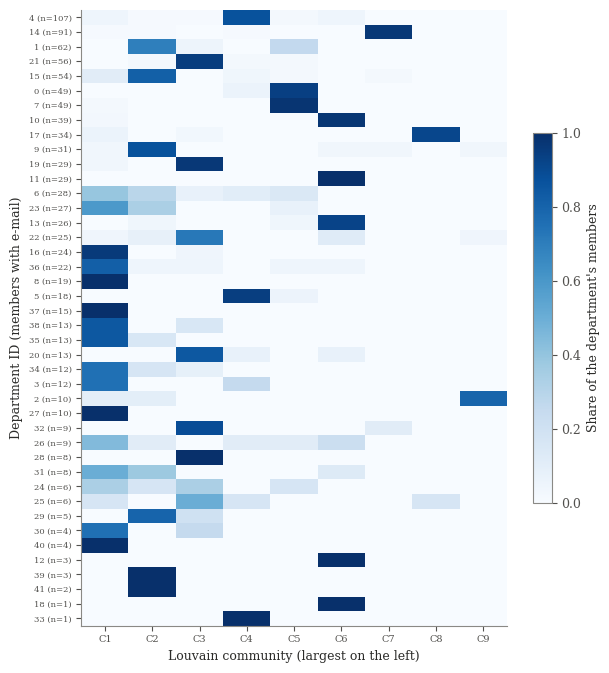

In [12]:
row_share = ct.div(ct.sum(axis=1), axis=0)
row_order = ct.sum(axis=1).sort_values(ascending=False).index
col_order = ct.sum(axis=0).sort_values(ascending=False).index
row_share = row_share.loc[row_order, col_order]

fig, ax = plt.subplots(figsize=(6.3, 6.8))
im = ax.imshow(row_share.values, aspect="auto", cmap="Blues", vmin=0, vmax=1, interpolation="nearest")
ax.set_yticks(range(len(row_order)))
ax.set_yticklabels([f"{d} (n={ct.loc[d].sum()})" for d in row_order], fontsize=6)
ax.set_xticks(range(len(col_order)))
ax.set_xticklabels([f"C{c + 1}" for c in col_order], fontsize=7)
ax.set_xlabel("Louvain community (largest on the left)")
ax.set_ylabel("Department ID (members with e-mail)")
cbar = fig.colorbar(im, ax=ax, shrink=0.6)
cbar.set_label("Share of the department's members")
fig.tight_layout()
fig.savefig(OUT / "fig_5_3_departments_vs_communities.png", dpi=200)
plt.show()

## Step 6 — H2b: Is the community result stable? (reliability)

Louvain is a **randomised** algorithm and depends on a **resolution** parameter γ (higher γ → more, smaller communities). If our conclusion only held for seed 42 and γ = 1, it would not be reliable.

1. **Seeds:** run Louvain with 20 different seeds (42 … 61); report the range of Q, NMI and ARI, and how similar each run is to the main run (NMI between partitions).
2. **Resolution:** γ ∈ {0.5, 1, 1.5, 2, 3}; report the number of communities, NMI and ARI. If NMI/ARI stay in a narrow band, the "match / no match" conclusion does not depend on γ. Q is always computed with the standard γ = 1 so the values are comparable.

In [13]:
def describe(partition):
    lab = {v: c for c, members in enumerate(partition) for v in members}
    cl = [lab[v] for v in connected]
    return (nx.community.modularity(U, partition), normalized_mutual_info_score(dept_labels, cl),
            adjusted_rand_score(dept_labels, cl), int(sum(len(c) > 1 for c in partition)), cl)


seed_rows = []
for s in range(SEED, SEED + N_SEEDS):
    Q, nmi_s, ari_s, k_s, cl = describe(nx.community.louvain_communities(U, seed=s))
    seed_rows.append({"seed": s, "Q": Q, "NMI vs departments": nmi_s, "ARI vs departments": ari_s,
                      "communities (size > 1)": k_s,
                      "NMI vs main run (seed 42)": normalized_mutual_info_score(comm_labels, cl)})
seeds = pd.DataFrame(seed_rows)
stability = seeds.drop(columns="seed").agg(["min", "median", "max"]).T
display(stability)
save_table(stability, "table_5_3_H2b_seed_stability", "Louvain over 20 seeds")

res_rows = []
for gamma in RESOLUTIONS:
    Q, nmi_g, ari_g, k_g, _ = describe(nx.community.louvain_communities(U, resolution=gamma, seed=SEED))
    res_rows.append({"resolution": gamma, "communities (size > 1)": k_g, "Q (gamma = 1)": Q,
                     "NMI vs departments": nmi_g, "ARI vs departments": ari_g})
resolution = pd.DataFrame(res_rows).set_index("resolution")
display(resolution)
save_table(resolution, "table_5_3_H2b_resolution", "Louvain resolution sensitivity")

summary["H2b"] = {"seeds": N_SEEDS,
                  "Q_range": [float(seeds["Q"].min()), float(seeds["Q"].max())],
                  "NMI_range": [float(seeds["NMI vs departments"].min()), float(seeds["NMI vs departments"].max())],
                  "ARI_range": [float(seeds["ARI vs departments"].min()), float(seeds["ARI vs departments"].max())],
                  "NMI_vs_main_min": float(seeds["NMI vs main run (seed 42)"].min()),
                  "resolution_table": resolution.reset_index().to_dict(orient="records")}

,min,median,max
Q,0.402116,0.413732,0.416933
NMI vs departments,0.531814,0.579039,0.602696
ARI vs departments,0.239352,0.305062,0.356620
communities (size > 1),7.000000,8.000000,9.000000
NMI vs main run (seed 42),0.691782,0.791375,1.000000


saved results/table_5_3_H2b_seed_stability.csv and .tex  (Louvain over 20 seeds)


,communities (size > 1),Q (gamma = 1),NMI vs departments,ARI vs departments
resolution,,,,
0.5,3,0.233449,0.293817,0.055429
1.0,9,0.413021,0.596288,0.355250
1.5,14,0.401641,0.670836,0.505628
2.0,24,0.381021,0.714208,0.578997
3.0,42,0.360909,0.729755,0.593790


saved results/table_5_3_H2b_resolution.csv and .tex  (Louvain resolution sensitivity)


## Step 7 — H3: How closed is each department? (E–I index)

**A:** assortativity gives **one** number for the whole institution. But some departments may be closed "silos" while others are open and work with everyone.

**B:** the **E–I index** (Krackhardt & Stern 1988; Borgatti et al. 2018) for each department, on the undirected (OR) network:

E–I = (E − I) / (E + I), with **E** = edges from members to people **outside** the department and **I** = edges **inside** it (each counted once).

- **−1** = all ties inside the department (a closed silo), **+1** = all ties outside.
- A raw E–I is hard to read, because a small department has few possible internal partners, so even random e-mailing would give E–I close to +1. So each department is compared with its **expected E–I under random mixing**: the same 5,000 label permutations as H1 (same department sizes, same network).
- **Test:** one-sided p = share of permutations with E–I ≤ observed (the department is *more closed* than chance). Because we test many departments at once, p-values are corrected with **Benjamini–Hochberg** (false discovery rate 5%).
- Departments with fewer than `MIN_DEPT_TEST` members are listed but not tested.

**Extra (H3b):** are large departments more closed than small ones? Spearman correlation between department size and the *gap* (observed − expected E–I).

In [14]:
internal_obs, external_obs, same_und_obs = ei_counts(dept)
ei_obs = ei_index(internal_obs, external_obs)
ei_whole = (m_und - 2 * same_und_obs) / m_und
p_ei_whole = p_lower(null_ei_whole, ei_whole)

no_internal = np.zeros(K, dtype=int)     # members with no tie to their own department
no_email = np.zeros(K, dtype=int)        # members with no e-mail at all
deg_internal = np.zeros(n, dtype=int)
same = dept[usrc] == dept[udst]
np.add.at(deg_internal, usrc[same], 1)
np.add.at(deg_internal, udst[same], 1)
deg_total = np.array([U.degree(v) for v in nodes])
for k in range(K):
    members = dept == k
    no_internal[k] = int(np.sum(members & (deg_internal == 0) & (deg_total > 0)))
    no_email[k] = int(np.sum(members & (deg_total == 0)))

ei = pd.DataFrame({
    "members": sizes, "internal edges I": internal_obs, "external edges E": external_obs,
    "E-I observed": ei_obs,
    "E-I expected": np.nanmean(null_ei_dept, axis=0),
    "expected 2.5%": np.nanpercentile(null_ei_dept, 2.5, axis=0),
    "expected 97.5%": np.nanpercentile(null_ei_dept, 97.5, axis=0),
    "members without internal tie": no_internal, "members without any e-mail": no_email,
}, index=pd.Index(dept_ids, name="department"))
ei["gap (obs - exp)"] = ei["E-I observed"] - ei["E-I expected"]

tested = (ei["members"] >= MIN_DEPT_TEST) & ei["E-I observed"].notna()
ei["p (more closed)"] = np.nan
ei.loc[tested, "p (more closed)"] = [p_lower(null_ei_dept[:, k], ei_obs[k]) for k in np.where(tested)[0]]
ei["p BH-adjusted"] = np.nan
ei.loc[tested, "p BH-adjusted"] = benjamini_hochberg(ei.loc[tested, "p (more closed)"].values)
ei["more closed than chance"] = np.where(tested, ei["p BH-adjusted"] < ALPHA, None)
ei = ei.sort_values("members", ascending=False)

pd.set_option("display.float_format", "{:.3f}".format)
pd.set_option("display.max_rows", 60)
display(ei)
save_table(ei, "table_5_3_H3_EI_all_departments", "E-I index, all 42 departments (appendix / GitHub)")

n_tested = int(tested.sum())
n_closed = int((ei["more closed than chance"] == True).sum())
rho, p_rho = spearmanr(ei.loc[tested, "members"], ei.loc[tested, "gap (obs - exp)"])
print(f"\nWhole institution: E-I = {ei_whole:.3f} (random mixing: {null_ei_whole.mean():.3f}), p = {p_ei_whole:.4f}")
print(f"Departments tested: {n_tested}; more closed than chance after BH correction: {n_closed}")
print(f"H3b: Spearman(size, gap) = {rho:.3f}, p = {p_rho:.4f}  (negative = larger departments are more closed)")

summary["H3"] = {"EI_whole": ei_whole, "EI_whole_expected": float(null_ei_whole.mean()),
                 "EI_whole_p": p_ei_whole, "departments_tested": n_tested,
                 "departments_more_closed_BH": n_closed,
                 "most_closed": ei.loc[tested].sort_values("gap (obs - exp)").head(5)[
                     ["members", "E-I observed", "E-I expected"]].reset_index().to_dict(orient="records"),
                 "most_open": ei.loc[tested].sort_values("gap (obs - exp)").tail(5)[
                     ["members", "E-I observed", "E-I expected"]].reset_index().to_dict(orient="records"),
                 "spearman_size_gap": rho, "spearman_p": p_rho}

,members,internal edges I,external edges E,E-I observed,E-I expected,expected 2.5%,expected 97.5%,members without internal tie,members without any e-mail,gap (obs - exp),p (more closed),p BH-adjusted,more closed than chance
department,,,,,,,,,,,,,
4,109,745,1889,0.434,0.887,0.858,0.915,6,2,-0.453,0.000,0.000,True
14,92,973,838,-0.075,0.906,0.879,0.931,2,1,-0.981,0.000,0.000,True
1,65,331,972,0.492,0.935,0.911,0.958,3,3,-0.443,0.000,0.000,True
21,61,355,901,0.435,0.940,0.917,0.962,10,5,-0.505,0.000,0.000,True
15,55,240,925,0.588,0.946,0.925,0.967,4,1,-0.358,0.000,0.000,True
7,51,433,683,0.224,0.950,0.928,0.970,1,2,-0.726,0.000,0.000,True
0,49,262,661,0.432,0.952,0.931,0.972,2,0,-0.520,0.000,0.000,True
10,39,292,874,0.499,0.962,0.942,0.981,1,0,-0.463,0.000,0.000,True
17,35,255,357,0.167,0.967,0.947,0.984,2,1,-0.800,0.000,0.000,True


saved results/table_5_3_H3_EI_all_departments.csv and .tex  (E-I index, all 42 departments (appendix / GitHub))

Whole institution: E-I = 0.329 (random mixing: 0.907), p = 0.0002
Departments tested: 35; more closed than chance after BH correction: 34
H3b: Spearman(size, gap) = -0.814, p = 0.0000  (negative = larger departments are more closed)


### Compact E–I table for the report (top 10 departments by size)

The full 42-row table is too long for a 5,000-word report: keep it on GitHub and put this short version in the text.

In [15]:
compact = ei.loc[tested].head(10)[["members", "E-I observed", "E-I expected", "gap (obs - exp)",
                                   "p BH-adjusted", "members without internal tie"]].copy()
compact.index = [f"Department {d}" for d in compact.index]
display(compact)
save_table(compact, "table_5_3_H3_EI_top10", "E-I index, 10 largest departments")

,members,E-I observed,E-I expected,gap (obs - exp),p BH-adjusted,members without internal tie
Department 4,109,0.434,0.887,-0.453,0.000,6
Department 14,92,-0.075,0.906,-0.981,0.000,2
Department 1,65,0.492,0.935,-0.443,0.000,3
Department 21,61,0.435,0.940,-0.505,0.000,10
Department 15,55,0.588,0.946,-0.358,0.000,4
Department 7,51,0.224,0.950,-0.726,0.000,1
Department 0,49,0.432,0.952,-0.520,0.000,2
Department 10,39,0.499,0.962,-0.463,0.000,1
Department 17,35,0.167,0.967,-0.800,0.000,2
Department 9,32,0.688,0.970,-0.282,0.000,3


saved results/table_5_3_H3_EI_top10.csv and .tex  (E-I index, 10 largest departments)


### Figure: observed vs. expected E–I per department

Grey line = range of E–I expected under random mixing (95% of permutations), blue dot = observed value. A dot far to the **left** of its grey line = a department much more closed than chance.

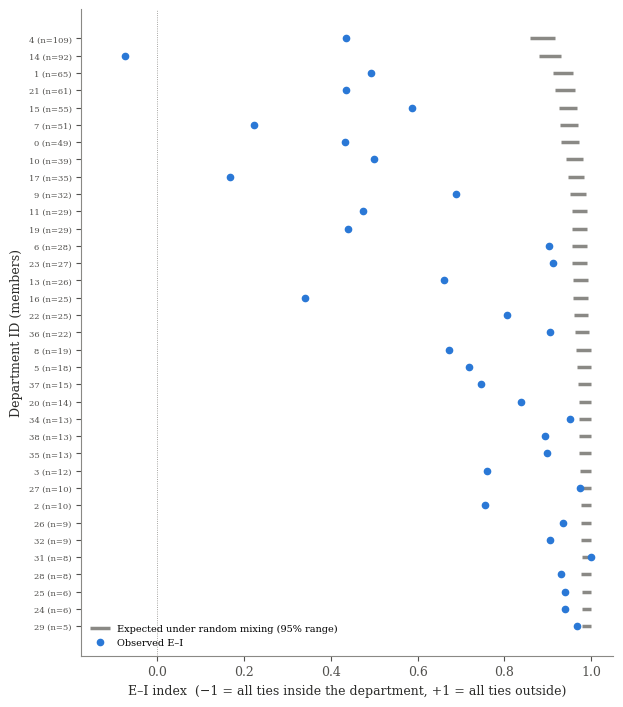

In [16]:
plot_df = ei.loc[tested].sort_values("members")
y = np.arange(len(plot_df))
fig, ax = plt.subplots(figsize=(6.3, 0.17 * len(plot_df) + 1.2))
ax.hlines(y, plot_df["expected 2.5%"], plot_df["expected 97.5%"], color=GREY, lw=2.5,
          label="Expected under random mixing (95% range)")
ax.plot(plot_df["E-I observed"], y, "o", color=BLUE, ms=4.5, label="Observed E–I")
ax.axvline(0, color=GREY, lw=0.6, ls=":")
ax.set_yticks(y)
ax.set_yticklabels([f"{d} (n={s})" for d, s in zip(plot_df.index, plot_df["members"])], fontsize=6)
ax.set_xlim(min(-0.1, plot_df["E-I observed"].min() - 0.1), 1.05)   # 0 always visible
ax.set_xlabel("E–I index  (−1 = all ties inside the department, +1 = all ties outside)")
ax.set_ylabel("Department ID (members)")
ax.legend(loc="lower left", fontsize=7, frameon=False)
fig.tight_layout()
fig.savefig(OUT / "fig_5_3_EI_departments.png", dpi=200)
plt.show()

## Step 8 — H4: Do the members outside a department's LCC really e-mail other departments?

Section 5.1 reports that in Departments 21 and 1, 24.6% and 13.8% of members are **outside the largest connected component** of their department network, and suggests their communication goes to other departments. Being outside the LCC can mean three different things, so we split every member of the 4 largest departments into:

1. **In the department's LCC**;
2. **Small own-department group**: has e-mail ties inside the department, but in a small separate piece;
3. **Only other departments**: no tie inside the department, but ties outside it → supports the claim in 5.1;
4. **No e-mail at all**: an isolate in the whole network → does *not* support the claim.

Groups 2–4 together must equal Person 1's "outside the LCC" share (the cell checks this).

In [17]:
rows = []
for d in largest_departments(G):
    H = dept_network(G, d).to_undirected()
    H_lcc = max(nx.connected_components(H), key=len)
    counts = {"in department LCC": 0, "small own-department group": 0,
              "only other departments": 0, "no e-mail at all": 0}
    for v in H.nodes():
        if U.degree(v) == 0:
            counts["no e-mail at all"] += 1
        elif H.degree(v) == 0:
            counts["only other departments"] += 1
        elif v not in H_lcc:
            counts["small own-department group"] += 1
        else:
            counts["in department LCC"] += 1
    total = H.number_of_nodes()
    outside = total - len(H_lcc)
    assert outside == total - counts["in department LCC"]
    rows.append({"department": f"Department {d}", "members": total, **counts,
                 "outside LCC (share)": outside / total,
                 "only other departments (share of outside)": counts["only other departments"] / outside if outside else np.nan})
h4 = pd.DataFrame(rows).set_index("department")
display(h4)
save_table(h4, "table_5_3_H4_outside_LCC", "who is outside the department LCC")
summary["H4"] = h4.reset_index().to_dict(orient="records")

,members,in department LCC,small own-department group,only other departments,no e-mail at all,outside LCC (share),only other departments (share of outside)
department,,,,,,,
Department 4,109,101,0,6,2,0.073,0.750
Department 14,92,89,0,2,1,0.033,0.667
Department 1,65,56,3,3,3,0.138,0.333
Department 21,61,46,0,10,5,0.246,0.667


saved results/table_5_3_H4_outside_LCC.csv and .tex  (who is outside the department LCC)


## Step 9 — H5: Are e-mails inside a department answered more often?

**A:** a boundary may not only make cross-department ties *rarer*, but also *weaker*: a message to another department may be more often a one-way notice than a conversation.

**B:** **reciprocity within departments** (share of within-department directed edges whose reverse edge also exists) vs. **reciprocity between departments**. Together they split the overall reciprocity of Section 5.1 (0.711); we do not repeat that number as a new result.

**Test:** the difference (within − between) is compared with the same 5,000 label permutations. One-sided p = share of permuted differences ≥ observed.

In [18]:
recip_within = reciprocated[within_dir].mean()
recip_between = reciprocated[~within_dir].mean()
diff_obs = recip_within - recip_between
p_recip = p_upper(null_recip_diff, diff_obs)

h5 = pd.DataFrame({
    "value": [recip_within, recip_between, diff_obs, null_recip_diff.mean(),
              np.percentile(null_recip_diff, 97.5), p_recip],
}, index=["Reciprocity, within departments", "Reciprocity, between departments",
          "Difference (within - between)", "Difference expected by chance (mean)",
          "Difference, 97.5% of permutations", "p-value (one-sided)"])
display(h5)
save_table(h5, "table_5_3_H5_reciprocity", "H5: reciprocity within vs between")
summary["H5"] = {"recip_within": recip_within, "recip_between": recip_between,
                 "difference": diff_obs, "null_mean": float(null_recip_diff.mean()), "p": p_recip,
                 "edges_within": int(within_dir.sum()), "edges_between": int((~within_dir).sum())}

,value
"Reciprocity, within departments",0.752
"Reciprocity, between departments",0.689
Difference (within - between),0.063
Difference expected by chance (mean),-0.000
"Difference, 97.5% of permutations",0.031
p-value (one-sided),0.000


saved results/table_5_3_H5_reciprocity.csv and .tex  (H5: reciprocity within vs between)


## Step 10 — Which departments talk to each other?

A descriptive view of the boundaries: the **department × department mixing matrix** (number of directed e-mail edges from members of row department to members of column department). The diagonal = within-department e-mail.

- Figure: log colour scale, because counts range from 0 to several hundred.
- Also saves `results/department_network.gexf`: a **weighted department-level network** (42 nodes, weight = number of edges between departments) that can be opened in **Gephi** for a nicer figure.
- Use it only if the word budget allows; otherwise mention it as available on GitHub.

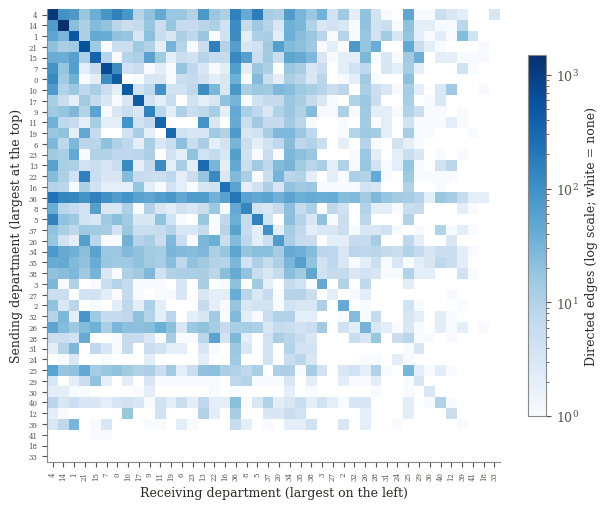

department pairs that exchange e-mail: 641 of 861
the 10 busiest department pairs carry 16.6% of all between-department edges


In [19]:
from matplotlib.colors import LogNorm

mix = np.zeros((K, K), dtype=int)
np.add.at(mix, (dept[src], dept[dst]), 1)
order = np.argsort(-sizes)
mix_df = pd.DataFrame(mix[np.ix_(order, order)], index=dept_ids[order], columns=dept_ids[order])
mix_df.to_csv(OUT / "department_mixing_matrix.csv")

fig, ax = plt.subplots(figsize=(6.3, 5.6))
im = ax.imshow(np.where(mix_df.values > 0, mix_df.values, np.nan), cmap="Blues",
               norm=LogNorm(vmin=1, vmax=mix.max()), interpolation="nearest")
ax.set_xticks(range(K)); ax.set_xticklabels(mix_df.columns, fontsize=5, rotation=90)
ax.set_yticks(range(K)); ax.set_yticklabels(mix_df.index, fontsize=5)
ax.set_xlabel("Receiving department (largest on the left)")
ax.set_ylabel("Sending department (largest at the top)")
cbar = fig.colorbar(im, ax=ax, shrink=0.7)
cbar.set_label("Directed edges (log scale; white = none)")
fig.tight_layout()
fig.savefig(OUT / "fig_5_3_department_mixing.png", dpi=200)
plt.show()

D = nx.Graph()
for k in range(K):
    D.add_node(int(dept_ids[k]), members=int(sizes[k]), internal_edges=int(internal_obs[k]))
for a in range(K):
    for b in range(a + 1, K):
        w = int(mix[a, b] + mix[b, a])
        if w > 0:
            D.add_edge(int(dept_ids[a]), int(dept_ids[b]), weight=w)
nx.write_gexf(D, OUT / "department_network.gexf")
between_total = int(mix.sum() - np.trace(mix))
top_pairs = sorted(((d["weight"], u, v) for u, v, d in D.edges(data=True)), reverse=True)
top10_share = sum(w for w, _, _ in top_pairs[:10]) / between_total
print(f"department pairs that exchange e-mail: {D.number_of_edges()} of {K * (K - 1) // 2}")
print(f"the 10 busiest department pairs carry {top10_share:.1%} of all between-department edges")
summary["mixing"] = {"dept_pairs_connected": D.number_of_edges(), "dept_pairs_possible": K * (K - 1) // 2,
                     "top10_pairs_share_of_between_edges": top10_share}

## Step 11: Numbers for Section 4 (Validity and Reliability)

Concrete facts to cite in Section 4, so it is not a generic text.

In [20]:
v_and_r = pd.DataFrame({"value": [
    f"{n} members, {K} departments, one department per member",
    f"{len(isolates)} members ({len(isolates) / n:.1%}) send and receive no e-mail inside the institution",
    f"{m_dir} directed edges after removing self-loops; SNAP's timestamped file reports the same number of static edges",
    f"{int(np.sum(sizes < MIN_DEPT_TEST))} departments have fewer than {MIN_DEPT_TEST} members (not tested in H3)",
    f"seed = {SEED}; {N_PERM} label permutations; {N_NULL} rewired networks; Louvain stability over {N_SEEDS} seeds",
    f"NetworkX {nx.__version__}, NumPy {np.__version__}, pandas {pd.__version__}",
]}, index=["population", "missing communication", "consistency with SNAP", "small groups",
           "randomness controlled", "software"])
display(v_and_r)
save_table(v_and_r, "table_4_validity_reliability_facts", "facts for Section 4", index=True)
summary["software"] = {"networkx": nx.__version__, "numpy": np.__version__, "pandas": pd.__version__}

,value
population,"1005 members, 42 departments, one department p..."
missing communication,19 members (1.9%) send and receive no e-mail i...
consistency with SNAP,24929 directed edges after removing self-loops...
small groups,7 departments have fewer than 5 members (not t...
randomness controlled,seed = 42; 5000 label permutations; 100 rewire...
software,"NetworkX 3.7, NumPy 2.4.6, pandas 2.2.3"


saved results/table_4_validity_reliability_facts.csv and .tex  (facts for Section 4)


## Step 12: Summary of all results + download

Prints every key number (also saved as `results/rq3_summary.json`), then zips the `results/` folder. **Send the zip (or this executed notebook) to the group / Claude for writing Sections 4, 5.3, 6.3 and 7.3**, and push the notebook to GitHub.

In [21]:
def to_builtin(x):
    if isinstance(x, dict):
        return {str(k): to_builtin(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        return [to_builtin(v) for v in x]
    if isinstance(x, (np.integer,)):
        return int(x)
    if isinstance(x, (np.floating, float)):
        return None if np.isnan(x) else round(float(x), 6)
    if isinstance(x, np.bool_):
        return bool(x)
    return x


summary_clean = to_builtin(summary)
(OUT / "rq3_summary.json").write_text(json.dumps(summary_clean, indent=2))
print(json.dumps(summary_clean, indent=2))

verdicts = pd.DataFrame({
    "result": [
        f"r = {r_obs:.3f}, QAP p = {p_r:.4f}; assortativity = {assort_obs:.3f}",
        f"Q_dept / Q_Louvain = {Q_dept / Q_louvain:.2f}; NMI = {nmi:.3f}, ARI = {ari:.3f}",
        f"NMI {seeds['NMI vs departments'].min():.3f}-{seeds['NMI vs departments'].max():.3f} over {N_SEEDS} seeds",
        f"{n_closed} of {n_tested} tested departments more closed than chance (BH)",
        "see table_5_3_H4_outside_LCC",
        f"within {recip_within:.3f} vs between {recip_between:.3f}, p = {p_recip:.4f}",
    ],
    f"supported at alpha = {ALPHA}?": [
        p_r < ALPHA, (p_Q_dept < ALPHA) and (p_nmi < ALPHA), "judge from ranges",
        n_closed > 0, "descriptive", p_recip < ALPHA],
}, index=["H1 homophily", "H2 communities ~ departments", "H2b stability",
          "H3 closed departments", "H4 outside the LCC", "H5 reciprocity"])
display(verdicts)
verdicts.to_csv(OUT / "rq3_verdicts.csv")

archive = shutil.make_archive("results_RQ3", "zip", OUT)
print("zipped:", archive)
try:
    from google.colab import files
    files.download(archive)
except ImportError:
    print("Not running in Colab: the results are in the 'results' folder and results_RQ3.zip.")

{
  "seed": 42,
  "n_perm": 5000,
  "n_null": 100,
  "nodes": 1005,
  "edges_directed": 24929,
  "edges_undirected": 16064,
  "departments": 42,
  "isolates": 19,
  "dept_size_min_median_max": [
    1,
    14.5,
    109
  ],
  "H1": {
    "share_within": 0.346785,
    "share_expected": 0.046667,
    "density_within": 0.183592,
    "density_between": 0.016928,
    "density_ratio": 10.845212,
    "assortativity": 0.314073,
    "assortativity_p": 0.0002,
    "qap_r": 0.226464,
    "qap_null_max": 0.009554,
    "qap_p": 0.0002
  },
  "H2": {
    "Q_louvain": 0.413021,
    "Q_dept": 0.288013,
    "Q_ratio": 0.697333,
    "Q_louvain_null_mean": 0.122105,
    "Q_louvain_p": 0.009901,
    "Q_dept_null_mean": -0.004289,
    "Q_dept_p": 0.009901,
    "nmi": 0.596288,
    "nmi_null_mean": 0.06232,
    "nmi_p": 0.000999,
    "ari": 0.35525,
    "n_communities_total": 28,
    "n_communities_size_gt1": 9,
    "largest_community": 190,
    "nodes_used_for_nmi_ari": 986,
    "weighted_purity": 0.43204

,result,supported at alpha = 0.05?
H1 homophily,"r = 0.226, QAP p = 0.0002; assortativity = 0.314",True
H2 communities ~ departments,"Q_dept / Q_Louvain = 0.70; NMI = 0.596, ARI = ...",True
H2b stability,NMI 0.532-0.603 over 20 seeds,judge from ranges
H3 closed departments,34 of 35 tested departments more closed than c...,True
H4 outside the LCC,see table_5_3_H4_outside_LCC,descriptive
H5 reciprocity,"within 0.752 vs between 0.689, p = 0.0002",True


zipped: /content/results_RQ3.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>